# Denna notebook analyserar intäckter mellan januari och juni, 2026.

## Börja med att importera nödvändiga bibliotek som analysen kräven

Källhänvisning 1: https://www.youtube.com/watch?v=hKCEjI3MT3Y&list=PLXkHB_gtvM_UqA_oVsyieSL-a1TYRUeYC&index=26
Källhänvisning 2: https://seaborn.pydata.org/index.html

In [548]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Importera försäljningsdatan
För att analysera datan måste vi först importera datasetet och konvertera det till en 'data frame'.

Källhänvisning 1: https://www.w3schools.com/python/pandas/pandas_csv.asp
Källhänvisning 2: Videolektion "4.4 – Rensa och sammanfatta data med Pandas", https://www.youtube.com/watch?v=dtHlNjruCfM&t=612s

In [549]:
df = pd.read_csv("../data/ecommerce_sales.csv")

### Inspektera datasetets innehåll, som exempelvis kolumnrubriker och datatyper. Ett snabbt sätt att göra detta är att använda "df.info()"

Källhänvisning 1: Videolektion "4.4 – Rensa och sammanfatta data med Pandas", https://www.youtube.com/watch?v=dtHlNjruCfM&t=612s
Källhänvisning 2: Videolektion "4.3 – Pandas och DataFrames", https://www.youtube.com/watch?v=TbiZkgoopy4&t=754s

In [550]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB


### För den här analysen så kommer data från kolumnen "date" att vara central, men just nu är "date" definierad som 'string'.Vi måste därför konvertera datatypen innan vi fortsätter. Samtidigt som vi gör det, så printar vi även äldsta och yngsta datum i tidsserien med hjälp av ".min())" och ".max())"

Källhänvisning: "4.4 – Rensa och sammanfatta data med Pandas", https://www.youtube.com/watch?v=dtHlNjruCfM&t=612s

In [551]:
df["date"] = pd.to_datetime(df["date"])
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

First date: 2024-01-01 00:00:00
Last date: 2024-06-30 00:00:00


## Så här långt kan vi se att tidsserien sträcker sig över en sex månader lång period. Detta inte är per definition dåligt, men det innebär det att datan är något begränsad sett till vilka sorts mönster vi kan urskönja över tid, som exempelvis säsongsbundna förändringar. Innan vi går vidare så är det även användbart att se över hur datan fördelar sig, det vill säga, vilken typ av distribution den har eftersom det kan ha konsekvenser för hur vi senare ska presentera försäljning över tid. Ett snabbt och enkelt sätt att se hur datan fördelar sig är att använda sig av ett låd-diagram, eller "boxplot".

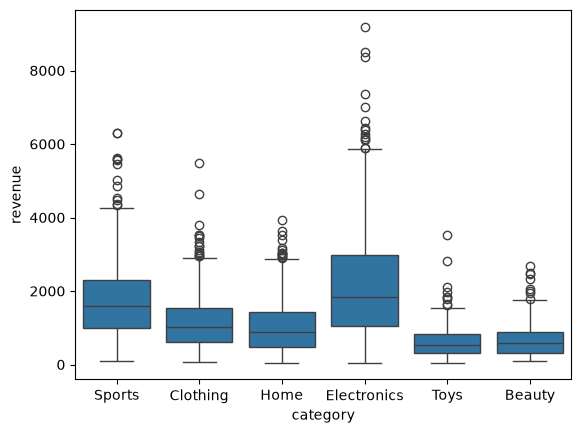

In [552]:
sns.boxplot(data=df, x="category", y="revenue")
plt.show()

#### Detta boxplot visar spridnignen av intäkter per kategori. Horisontella streck innanför varje låda visar median i intäkt. Tomma cirklar visar på eventuella extremvärden (outliers). Detta boxplot visar på att samtliga kategorier är relativt lika i intäkt, med undantag för elektronik, även om median-intäkt inte är extremt mycket högre än övriga kategorier. Däremot kan vi se att elektronik har den mest skeva distributionen i intäkt, med intäktsvärden som är både väldigt låga samt väldigt höga. Detta gäller även i fallande ordning Sports, Clothing, Home, medan Toys och Beauty har relativt jämförbara intäktssiffror. Detta innebär att vi lämpligen bör utforska tre olika värden när vi jämför försäljning över tid: total, genomsnitt och median. Innan vi går vidare så kan vi även se på hur antalet enheter fördelar sig per kategori, vi kan snabbt återanvända samma boxplot som vi skapade tidigare, men istället för "y="revenue" använder vi "y="units".


Källhänvisning: "5.2 - Välj rätt figur", https://www.youtube.com/watch?v=uFGfAxOnkqs&list=PLXkHB_gtvM_UqA_oVsyieSL-a1TYRUeYC&index=28

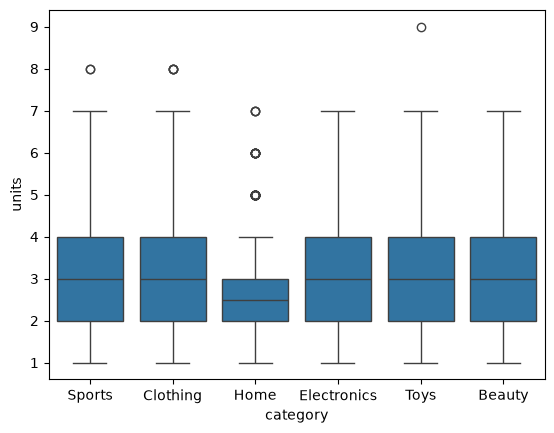

In [553]:
sns.boxplot(data=df, x="category", y="units")
plt.show()

#### Detta boxplot visar att spridningen i antalet sålda enheter per kategori är betydligt mindre i jämförelse till varandra, med undantag för kategorin Home. Här kan det därför bli mindre relevant att exempelvis jämföra median av antalet sålda enheter. Istället bör fokus riktas på total eller genomsnitt.   

# Analys över tid

#### Nu kan vi gå vidare med att göra våra beräkningar. Vi såg från spridningen i datan att det finns skäl att jämföra olika mått för både intäkt och antalet såld enheter. För att inte behöva göra flertalet beräkningar om och om igen, så kan vi använda oss av ett par funktioner. Vi kommer jämföra summa, median och genomsnitt per vecka och månad. Vi skapar därmed 3 olika funktioner. För våra olika funktioner behöver vi använda oss ett uttryck som bestämmer hur våra värdens skall beräknas. vi kommer därför att använda oss utav: .sum(), .median(), .mean().


källhänvisning 1: "2.1 - Funktioner och moduler", https://www.youtube.com/watch?v=v7jybHyE56M

källhänvisning 2: https://www.w3schools.com/python/pandas/ref_df_groupby.asp

In [554]:
# Följande funktion räknar ut den totala intäkten per tidsenhet
def total_revenue(data, frequency):
    result = (
        data.groupby(pd.Grouper(key="date", freq=frequency))["revenue"]
        .sum()
        .reset_index()
    )
    return result

weekly_revenue_total = total_revenue(df, frequency="W")

# Följande funktion räknar ut den totala intäkten per tidsenhet
def mean_revenue(data, frequency):
    result = (
        data.groupby(pd.Grouper(key="date", freq=frequency))["revenue"]
        .mean()
        .reset_index()
    )
    return result

weekly_revenue_mean = mean_revenue(df, frequency="W")

# Följande funktion räknar ut den totala intäkten per tidsenhet
def median_revenue(data, frequency):
    result = (
        data.groupby(pd.Grouper(key="date", freq=frequency))["revenue"]
        .median()
        .reset_index()
    )
    return result

weekly_revenue_median = median_revenue(df, frequency="W")

# Funktioner för antalet enheter
def total_units(data, frequency):
    result = (
        data.groupby(pd.Grouper(key="date", freq=frequency))["units"]
        .sum()
        .reset_index()
    )
    return result

weekly_units_total = total_units(df, frequency="W")

# # Funktioner för antalet enheter
def mean_units(data, frequency):
    result = (
        data.groupby(pd.Grouper(key="date", freq=frequency))["units"]
        .mean()
        .reset_index()
    )
    return result

weekly_units_mean = mean_units(df, frequency="W")

# Funktioner för antalet enheter
def median_units(data, frequency):
    result = (
        data.groupby(pd.Grouper(key="date", freq=frequency))["units"]
        .median()
        .reset_index()
    )
    return result

weekly_units_median = median_units(df, frequency="W")

# Funktion för intäkt per kategori och tidsperiod
def total_revenue_by_category(data, frequency):
    result = (
        data.groupby(["category", pd.Grouper(key="date", freq=frequency)])["revenue"]
        .sum()
        .reset_index()
    )
    return result

weekly_total_revenue_by_category = total_revenue_by_category(df, frequency="W")

# Funktion för intäkt per kategori och tidsperiod
def mean_revenue_by_category(data, frequency):
    result = (
        data.groupby(["category", pd.Grouper(key="date", freq=frequency)])["revenue"]
        .mean()
        .reset_index()
    )
    return result

weekly_mean_revenue_by_category = mean_revenue_by_category(df, frequency="W")

# Funktion för intäkt per kategori och tidsperiod
def median_revenue_by_category(data, frequency):
    result = (
        data.groupby(["category", pd.Grouper(key="date", freq=frequency)])["revenue"]
        .median()
        .reset_index()
    )
    return result

weekly_median_revenue_by_category = median_revenue_by_category(df, frequency="W")

##
# Följande funktion räknar ut antalet sålda enhehter per kategori och tidsperiod
def total_units_by_category(data, frequency):
    result = (
        data.groupby(["category", pd.Grouper(key="date", freq=frequency)])["units"]
        .sum()
        .reset_index()
    )
    return result

weekly_total_units_by_category = total_units_by_category(df, frequency="W")

# Följande funktion räknar ut antalet sålda enhehter per kategori och tidsperiod
def mean_units_by_category(data, frequency):
    result = (
        data.groupby(["category", pd.Grouper(key="date", freq=frequency)])["units"]
        .mean()
        .reset_index()
    )
    return result

weekly_mean_units_by_category = mean_units_by_category(df, frequency="W")

# Följande funktion räknar ut antalet sålda enhehter per kategori och tidsperiod
def median_units_by_category(data, frequency):
    result = (
        data.groupby(["category", pd.Grouper(key="date", freq=frequency)])["units"]
        .median()
        .reset_index()
    )
    return result

weekly_median_units_by_category = median_units_by_category(df, frequency="W")

## Skapa linjediagram över totala intäkter per vecka.


Källhänvisning: https://seaborn.pydata.org/generated/seaborn.lineplot.html

Denna källhänvisning gäller för samtliga linjediagram som följer nedan.

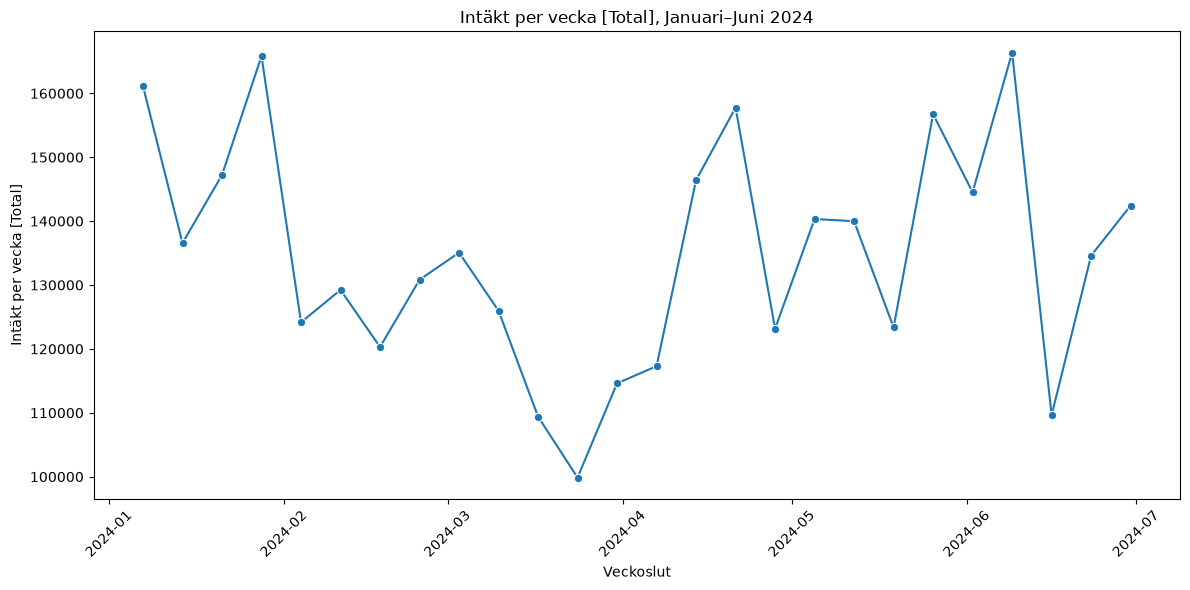

In [555]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_revenue_total,
    x="date",
    y="revenue",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Intäkt per vecka [Total]")
plt.title("Intäkt per vecka [Total], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

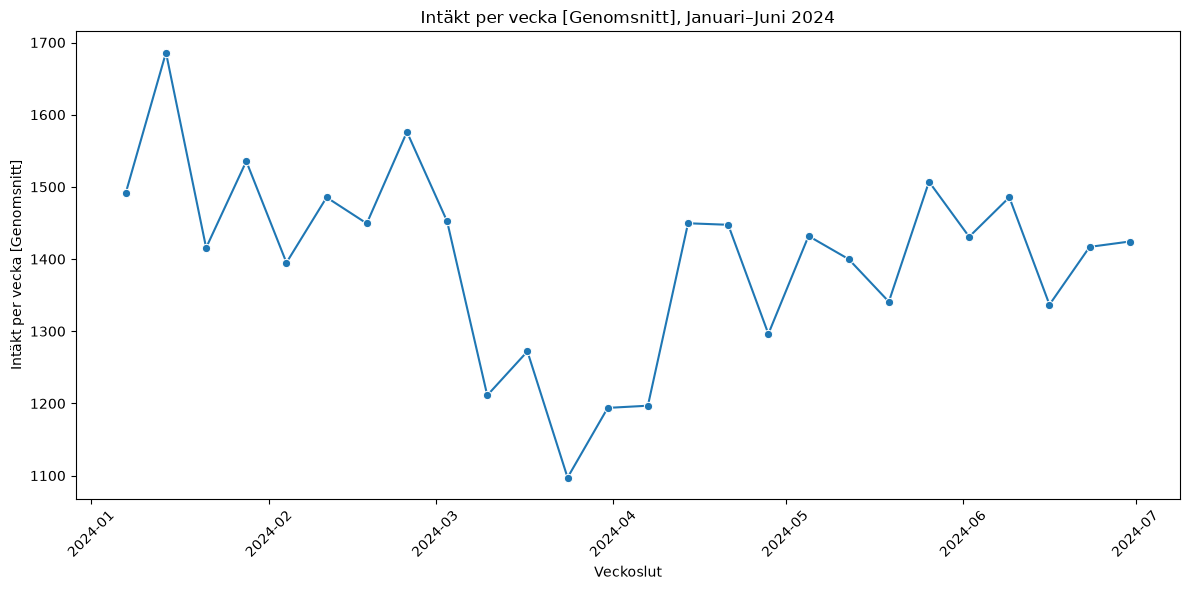

In [556]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_revenue_mean,
    x="date",
    y="revenue",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Intäkt per vecka [Genomsnitt]")
plt.title("Intäkt per vecka [Genomsnitt], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

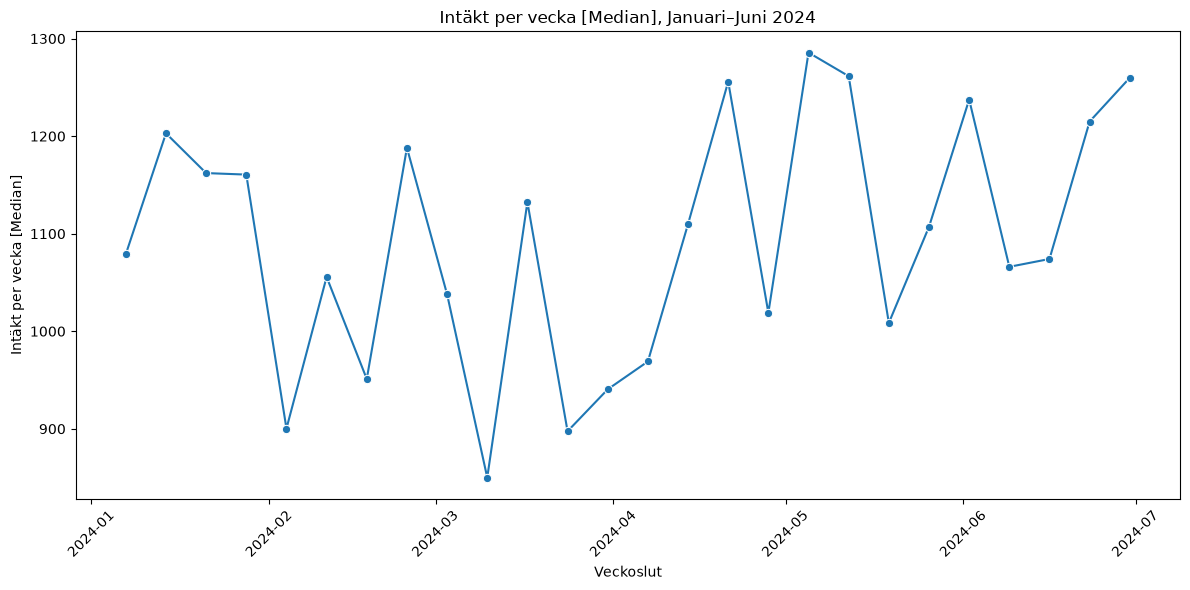

In [557]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_revenue_median,
    x="date",
    y="revenue",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Intäkt per vecka [Median]")
plt.title("Intäkt per vecka [Median], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Skapa grafer över sålda enheter per vecka.

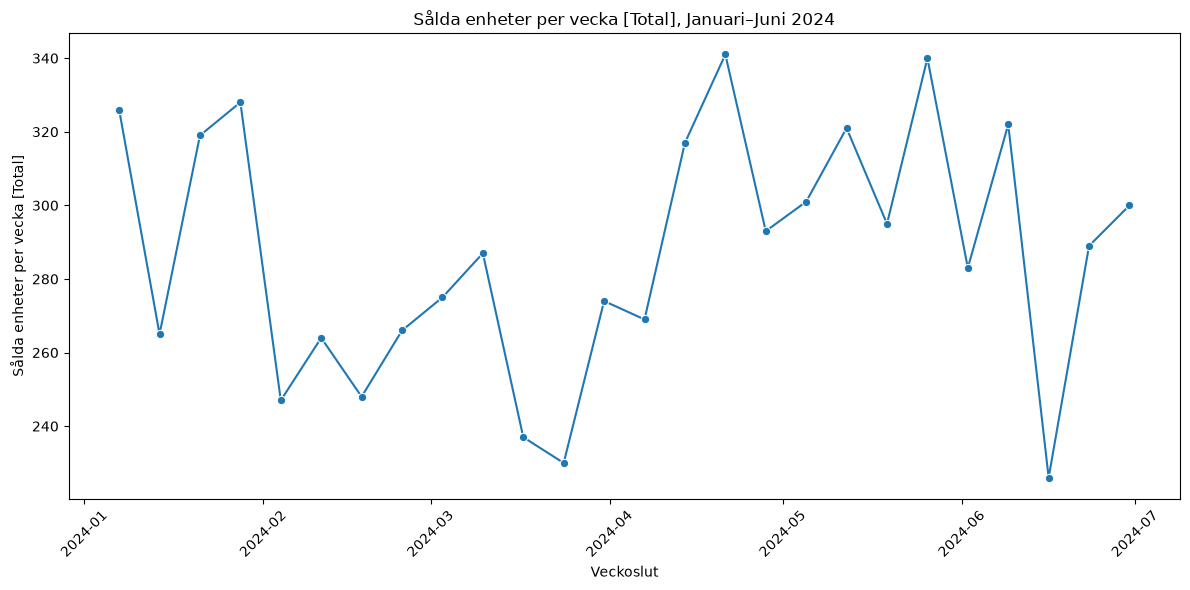

In [558]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_units_total,
    x="date",
    y="units",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Sålda enheter per vecka [Total]")
plt.title("Sålda enheter per vecka [Total], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

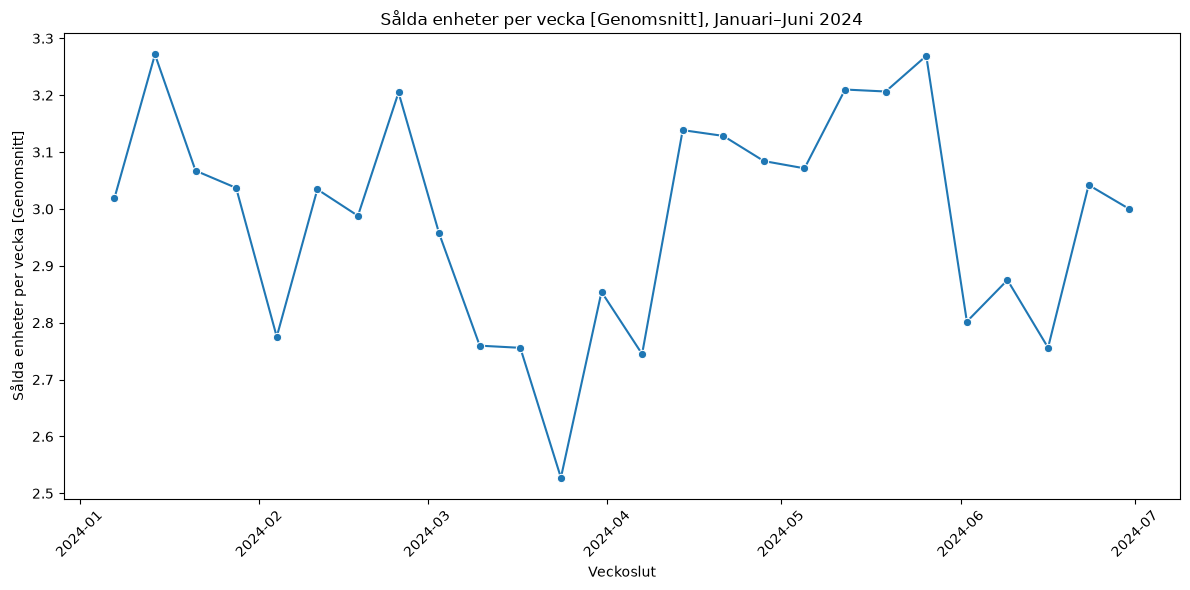

In [559]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_units_mean,
    x="date",
    y="units",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Sålda enheter per vecka [Genomsnitt]")
plt.title("Sålda enheter per vecka [Genomsnitt], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

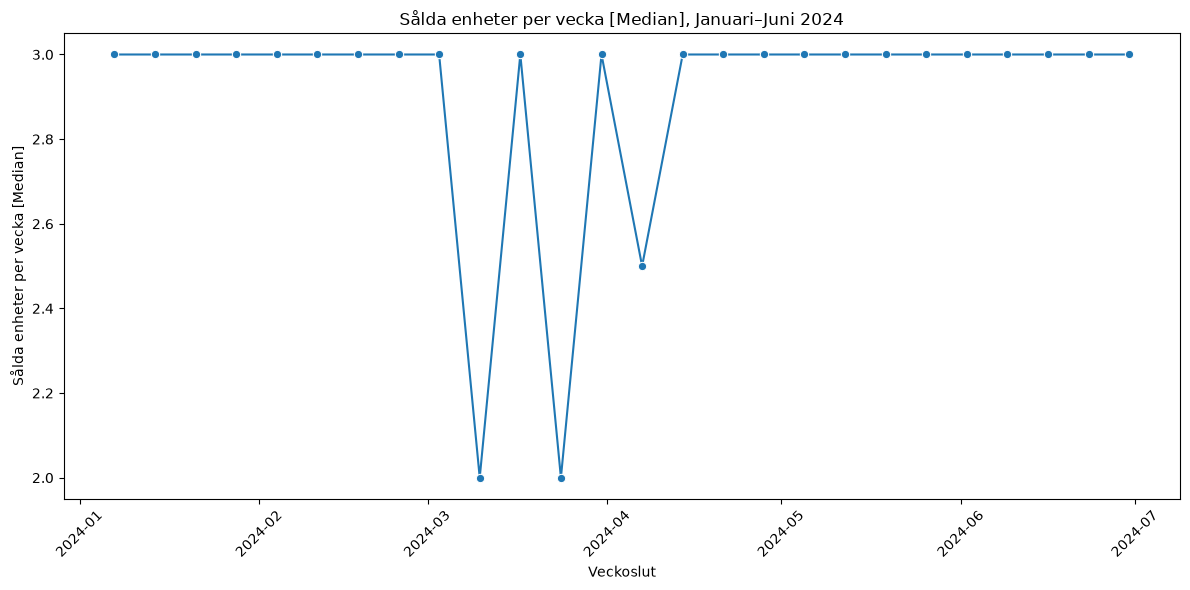

In [560]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_units_median,
    x="date",
    y="units",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Sålda enheter per vecka [Median]")
plt.title("Sålda enheter per vecka [Median], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Skapa grafer över intäkt per vecka per kategori

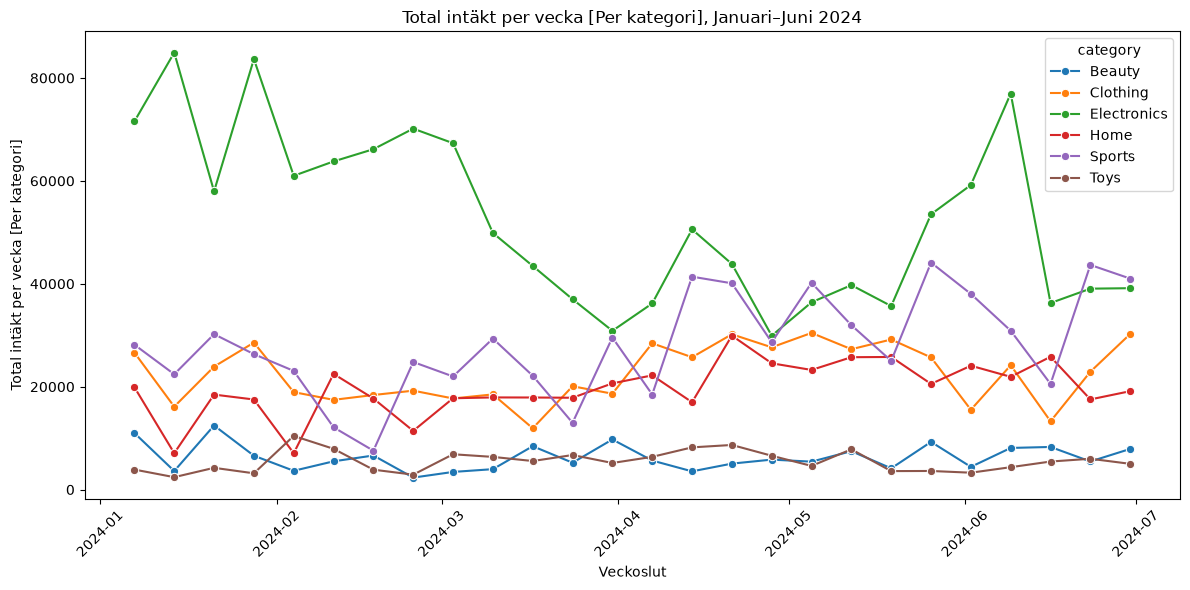

In [561]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_total_revenue_by_category,
    x="date",
    y="revenue",
    hue="category",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Total intäkt per vecka [Per kategori]")
plt.title("Total intäkt per vecka [Per kategori], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

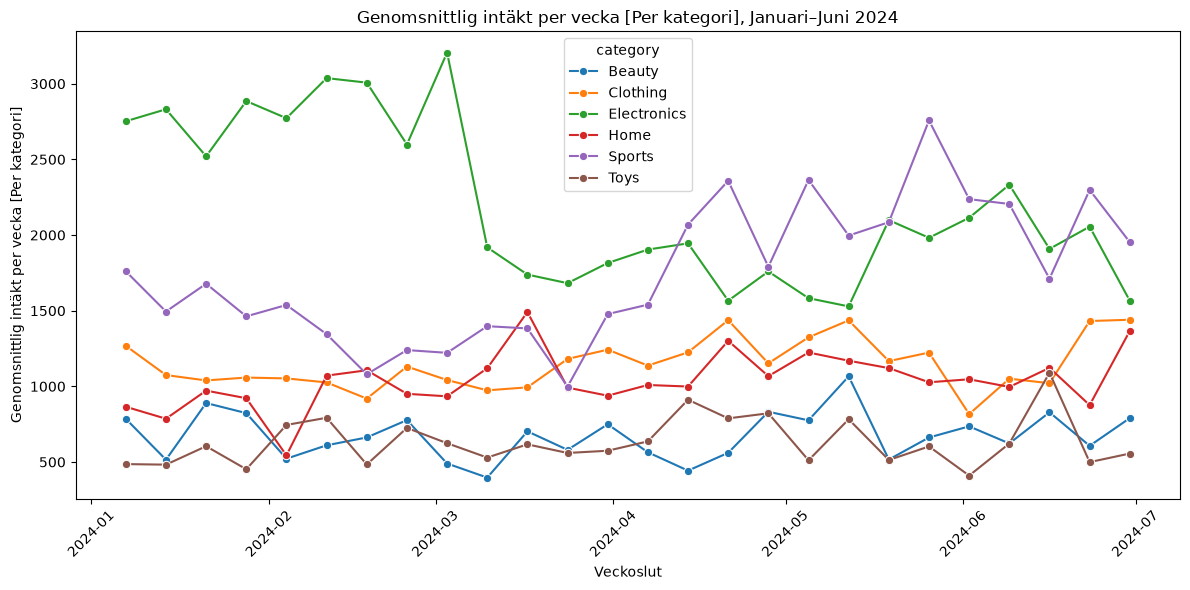

In [562]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_mean_revenue_by_category,
    x="date",
    y="revenue",
    hue="category",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Genomsnittlig intäkt per vecka [Per kategori]")
plt.title("Genomsnittlig intäkt per vecka [Per kategori], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

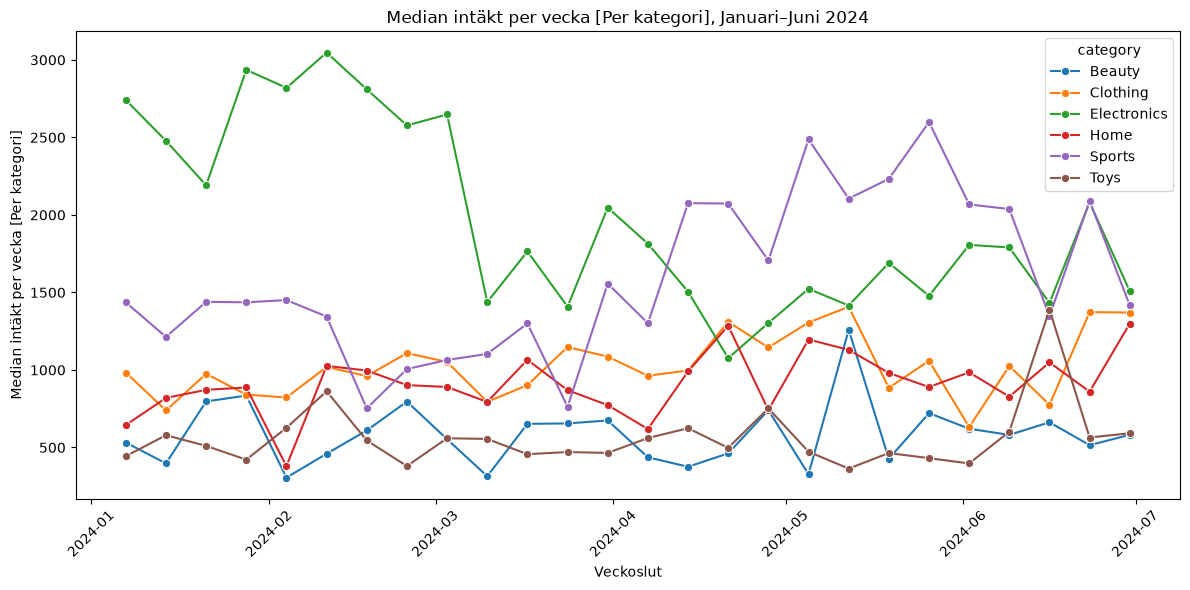

In [563]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_median_revenue_by_category,
    x="date",
    y="revenue",
    hue="category",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Median intäkt per vecka [Per kategori]")
plt.title("Median intäkt per vecka [Per kategori], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Skapa grafer över antalet sålda enheter per vecka per kategori

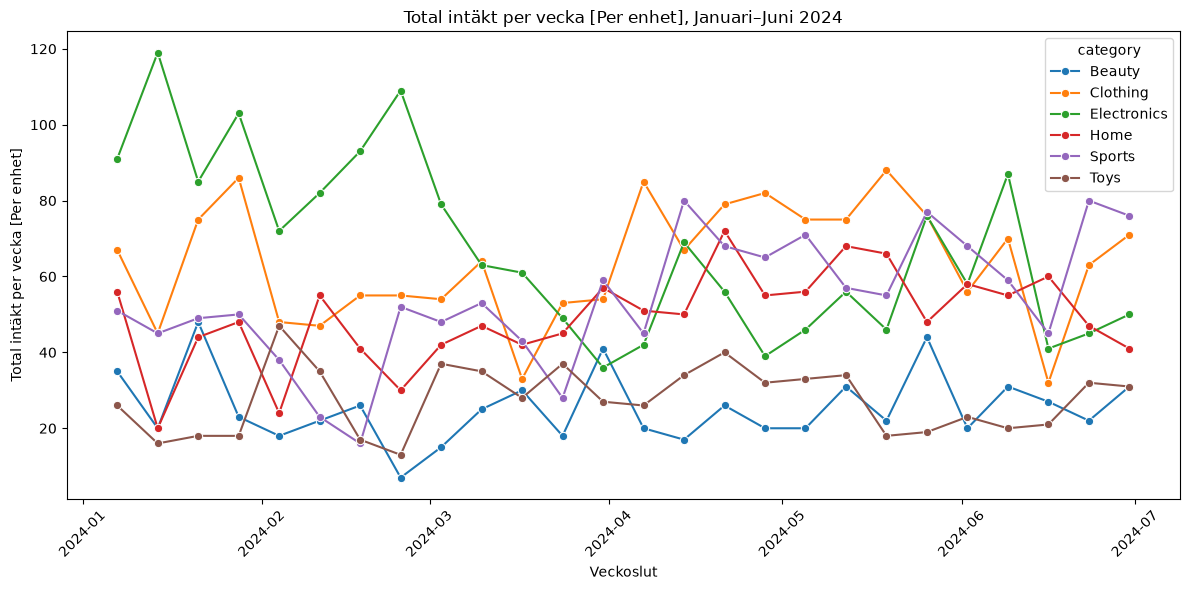

In [564]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_total_units_by_category,
    x="date",
    y="units",
    hue="category",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Total intäkt per vecka [Per enhet]")
plt.title("Total intäkt per vecka [Per enhet], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

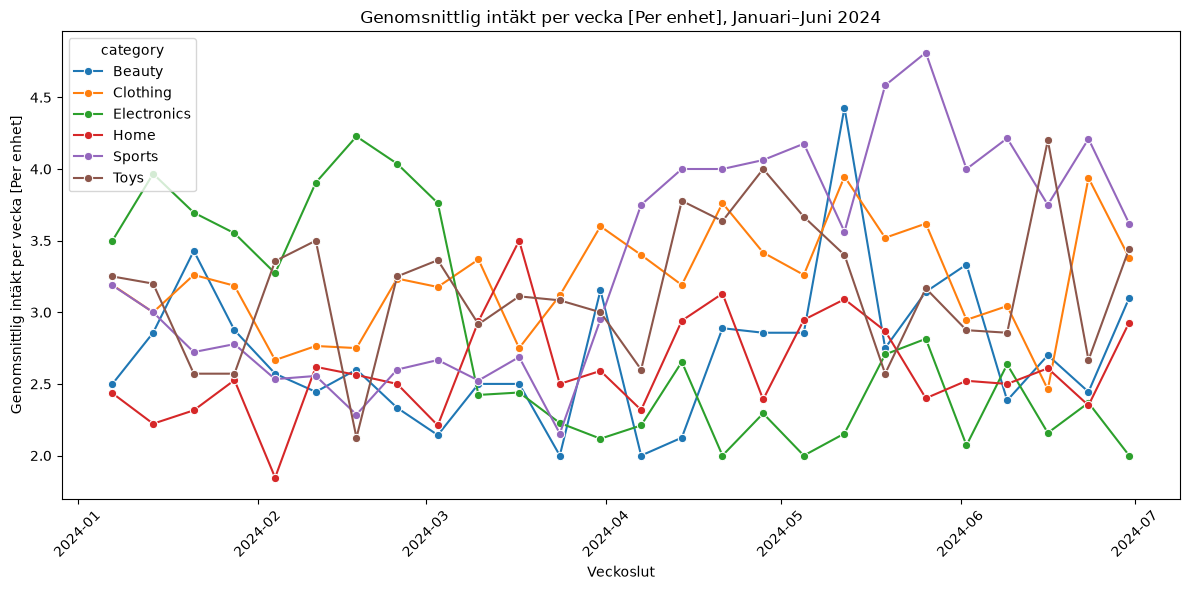

In [565]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_mean_units_by_category,
    x="date",
    y="units",
    hue="category",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Genomsnittlig intäkt per vecka [Per enhet]")
plt.title("Genomsnittlig intäkt per vecka [Per enhet], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

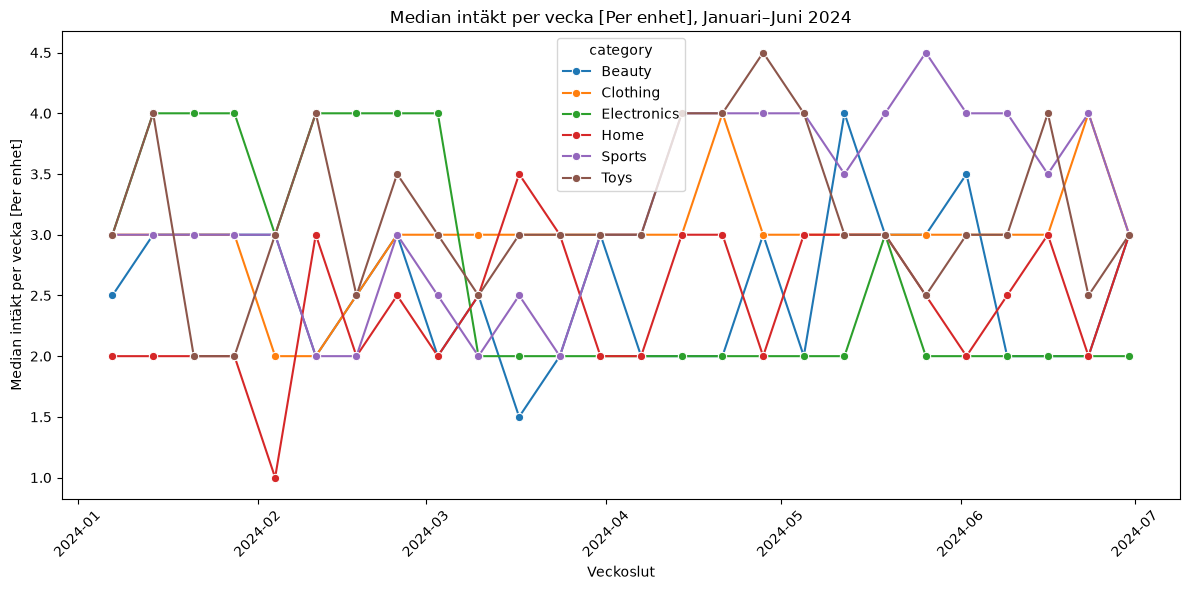

In [566]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_median_units_by_category,
    x="date",
    y="units",
    hue="category",
    marker="o"
)

plt.xlabel("Veckoslut")
plt.ylabel("Median intäkt per vecka [Per enhet]")
plt.title("Median intäkt per vecka [Per enhet], Januari–Juni 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Tolkning: Totala intäkter och sålda enheter per vecka
- Spridningen i intäkter är relativt jämn tvärs över samtliga kategorier, men undantag kan skådas i kategorin "Electronics". Det betyder att jämförelse i intäkter över bäst analyseras genom att överväga summa, genomsnitt och median. Spridningen är antalet sålda enheter visade sig dock vara oerhört jämn, med undantag för kategorin "Home". Jämförslser över antalet såld enheter över tid kan därför också analyseras med hjälp av summa, genomsnitt och median, även om den sisnämnda visade sig vara mindre informativ.
- Den totala och genomsnittliga intäkten per vecka sjunker drastiskt mellan februari och april. Median-intäkt visar inte alls på samma minskning under denna period, utan tycks vara något mer jämn över inmätningsperioden, förvisso med fluktuationer. 
- Samma nedgång mellan februari och april kan även skådas i totalt samt genomsnittligt sålda enheter, även om genomsnitt inte visar på en lika stadig nedgång som totalt. Som förväntat så var median i antalet sålda enheter inte så informativt, utan höll sig kring 3 sålda enheter per vecka under hela inmätningsperioden, med undantag för enn drastisk minskning mellan hela mars månad och inledningsvis i april månad.

### Tolkning: Totala intäkter och sålda enheter per vecka/kategori
- Om man analyserar dessa mönster per kategori, så ser man att kategorin "Electronics" är mest bidragande till den totala intäkten per vecka för inmätningsperioden, och detta är ett mönster som tycks hålla sig vare sig det är total, genomsnitt eller median intäkt. Under samma period som "Electronics" minskar, så ökar intäkterna i katergorierna "Home", "Sports" och "Clothing". Ser man till genomsnitt och median så överstiger till och med dessa tre kategorier "Electronics". Intäkter för kategorier som exempelvis "Toys" och "Beauty" visar sig vara mest stabila under inmätningsperioden, men dessa bidrar med minst intäkter totalt sett oavsett om man ser på total, genomsnitt eller median.

### Tolkning: Totala intäkter och sålda enheter per vecka/kategori
- När det gäller sålda enheter per vecka, så ser man att minskningen i total, genomsnittlig och median intäkt för "Electronics" huvdsakligen sammanfaller med en minskning i antalet sålda enheter. Det motsatta mönstret verkar dock gälla för kategorierna "Home", "Sports" och "Clothing" där både ökade intäkter tycks sammanfalla med ett ökat antal sålda enheter per kategori. Något otydligare är detta mönster om man ser till medianen, där flertalet kategorier, som tidigare nämnt, tycks sälja relativt lika.

### Sammanfattning
- Intäkter per vecka tycks fluktuera markant i flertalet kategorier under inmätningsperioden januari-juni 2024. Den kategori som bidrar mest till dessa fluktuationer tycks vara kategorin "Electronics", som sjunker i både intäkter och antalet sålda enheter från och med februari månad och utmed resten av inmätningsperioden. Det motsatta mönstret kan skådas i kategorier som exempelvis "Home", "Sports" och "Clothing" där ökade intäkter tycks följa med en ökning i antalet sålda enheter. Svängningar i intäkter mellan månader som sammanfaller under vinterhalvåret kontra månader som sammanfaller under sommarhalvåret är ett intressant och avvikande mönster i datan. Huruvida detta är ett faktiskt tecken på en årligt återkommande säsongscykel är dock för tidigt att avgöra eftersom datan endast sträcker sig över ett halvt år.

- Mest stabil över tid, men förvisso med lägst intäkter och sålda enheter, har vi kategorierna "Beauty" och "Toys". Här är försäljningen såpass stabil att det inte går att urskönja några tydliga mönster likt tidigare nämnda kategorier: försäljning av dessa kategorier får därmed summeras som bra trots att intäkter inom respektive skulle kunna öka.


## Rekomendationer
- Försök att göra en mer detaljerad undersökning om varför "Electronics" sjunker så markant från och med februari och framåt, möjligtvis genom att komplettera datasetet med variabler som berör köpkraft hos konsumenter, eller försäljningsstrategier för varje enskild butik.
- Detsamma kan göras för kategorierna "Toys" och "Beauty". Dessa säljer förvisso bra över tid, men strategier för att öka intäkter från dessa bör undersökas vidare.
- En möjligt tendens till säsongsbunden försäljning kan även skådas hos kategorier som "Home", "Sports" och "Clothing". Men, datasetet är begränsat till endast 6 månader, så uttökad datainsamling krävs för att undersöka detta vidare. Om ett utökat dataset skulle förstärka bilden av en säsongsbunden försäljning hos dessa kategorier så kan strategier tas fram för att öka försäljningen under de månader som just nu säljer i låga volymer.